# WP10 — Atom–bağ grafı tasarımı ve uygulanabilirlik

Aktif ROADMAP WP10: SMILES→atom/bond graf,RDKit→PyG Data,readout,küçük moleküler GNN ve kademeli karşılaştırma;veri yetersizse deney ertelenir. **Bu aşama yalnız tasarım ve gerçek yapı incelemesidir. Model,PyG eğitim nesnesi veya optimizer oluşturulmadı.**

Kaynaklar WP04'te yerel DrugBank XML'den çıkarılan SMILES ve doğrulanmış CID köprüsüdür. Bunlara canlı PubChem yapısı yeniden doğrulanmış denmez. Yeni molekül,etiket veya veri kaynağı indirilmedi.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP10/design_v1';F=ROOT/'reports/figures/WP10/design_v1';F.mkdir(parents=True,exist_ok=True)
summary=json.loads((Q/'feasibility_summary.json').read_text(encoding='utf-8'))
proposal=json.loads((ROOT/'configs/WP10_design_PROPOSED_v1.json').read_text(encoding='utf-8'))
data=pd.read_csv(Q/'molecular_graph_feasibility_all62.csv')
display(pd.DataFrame([summary]).T.rename(columns={0:'sonuç'}));display(data)
display(pd.DataFrame([json.loads((Q/'runtime_readiness.json').read_text(encoding='utf-8'))]))


,sonuç
source_records,62
parse_and_local_key_match,62
technical_graph_possible,62
QC_clear_proposed_atom_mask,54
QC_review_pending,8
atoms_total,2061
bonds_total,2219
atoms_min,10
atoms_max,125
multi_component_records,1


,id,name,cid,source_kind,technical_graph_possible,strict_QC_pass_unchanged,review_flags,proposed_atom_modality_eligible_PENDING_APPROVAL,atoms,bonds,directed_edges_if_materialized,components,unassigned_atom_stereo,unassigned_double_stereo,max_degree,source_SMILES_sha256
0,DB00199,Erythromycin,12560,local_DrugBank_XML,True,True,NaN,True,51,53,106,1,0,0,4,3730525c6f4b64b2431e1c6dfc74f024c1281ba215f45193f0da02f19158c51c
1,DB00207,Azithromycin,447043,local_DrugBank_XML,True,True,NaN,True,52,54,108,1,0,0,4,c4906a6e76e2e07e99b54f2c51b790625097744a91b2e90303fe6e8b6fb448b5
2,DB00254,Doxycycline,54671203,local_DrugBank_XML,True,True,NaN,True,34,37,74,1,0,0,4,0a23470cbd5236623d8fd1596ebe09a065826f9d4d776ef8b6fece4f3be17032
3,DB00259,Sulfanilamide,5333,local_DrugBank_XML,True,True,NaN,True,11,11,22,1,0,0,4,59a499fd2991923be348220eae1f11bb4edcf1c825df23fcb7222886bf839f50
4,DB00301,Flucloxacillin,21319,local_DrugBank_XML,True,True,NaN,True,31,34,68,1,0,0,4,4756fbde1a6a7fbf5e17be742194589b49bd3eff6f5f40141f3578415d603fc5
5,DB00303,Ertapenem,150610,local_DrugBank_XML,True,True,NaN,True,37,40,80,1,0,0,4,6c5a942a7f540f397c286d594a426cd85e35c79a4608f486074f55b64259b387
6,DB00319,Piperacillin,43672,local_DrugBank_XML,True,True,NaN,True,37,40,80,1,0,0,4,91854bd151b31a4fa57099003f4689b488ea26db4ad5310651451e88b29c3404
7,DB00359,Sulfadiazine,5215,local_DrugBank_XML,True,True,NaN,True,17,18,36,1,0,0,4,9195aade8b5abd500d72f1076255e1aa55df09cb98a183edd04eb04817d6d91f
8,DB00415,Ampicillin,6249,local_DrugBank_XML,True,True,NaN,True,25,27,54,1,0,0,4,78fa6f7a05e3945a96d69ad8626f9391a6f66d1db20c3dc64fda13db6afe29d2
9,DB00417,Phenoxymethylpenicillin,6869,local_DrugBank_XML,True,True,NaN,True,25,27,54,1,0,0,4,cdc52de72bebc09fd656b1221dbcf3f10baf5a015de23b7d97250553c9bee371


,default_path_PyG_available,project_local_PyG_import_verified,project_path,version,install_performed,model_or_Data_constructed
0,False,True,.deps/pyg,2.8.0,False,False


**Yorum:**62/62 ayrıştırma,yerel tam anahtar ve atom/bağ sayımı yeniden doğrulandı.2061 atom/2219 bağ;10–125 atom/ilaç. Bunlar gözlenen yapı boyutlarıdır,bağımsız eğitim örneği sayısı62'yi artırmaz. Varsayılan import yolunda PyG görünmese de mevcut `.deps/pyg` paketi ayrıca import edilip doğrulandı;yeni kurulum gerekmedi.

## 1. Teknik uygunluk ile QC onayı

,id,name,review_flags,atoms,bonds,components,proposed_atom_modality_eligible_PENDING_APPROVAL
0,DB00578,Carbenicillin,unspecified_atom_stereo,27,29,1,False
1,DB00798,Gentamicin,multiple_components|unspecified_atom_stereo,105,111,3,False
2,DB00978,Lomefloxacin,unspecified_atom_stereo,25,27,1,False
3,DB01044,Gatifloxacin,unspecified_atom_stereo,27,30,1,False
4,DB01150,Cefprozil,unspecified_double_bond_stereo,29,31,1,False
5,DB01155,Gemifloxacin,unspecified_atom_stereo,28,31,1,False
6,DB01165,Ofloxacin,unspecified_atom_stereo,26,29,1,False
7,DB06799,Methenamine,unspecified_atom_stereo,10,12,1,False


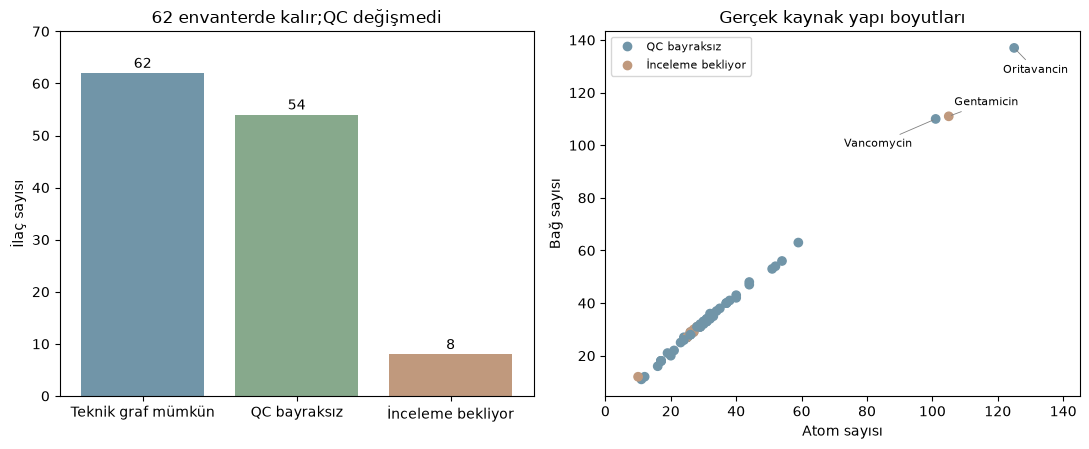

In [2]:

review=pd.read_csv(Q/'QC_review_eight_preserved.csv');display(review[['id','name','review_flags','atoms','bonds','components','proposed_atom_modality_eligible_PENDING_APPROVAL']])
fig,axs=plt.subplots(1,2,figsize=(11,4.6))
axs[0].bar(['Teknik graf mümkün','QC bayraksız','İnceleme bekliyor'],[62,54,8],color=['#7195a8','#87a98c','#c0997d']);axs[0].set(ylabel='İlaç sayısı',title='62 envanterde kalır;QC değişmedi',ylim=(0,70))
for i,v in enumerate([62,54,8]):axs[0].text(i,v+1,str(v),ha='center')
axs[1].scatter(data.atoms,data.bonds,c=np.where(data.strict_QC_pass_unchanged,'#7195a8','#c0997d'))
axs[1].set(xlabel='Atom sayısı',ylabel='Bağ sayısı',title='Gerçek kaynak yapı boyutları')
axs[1].set_xlim(0,145)
offsets={'DB00798':(4,8),'DB04911':(-8,-18),'DB00512':(-66,-20)}
for d in ['DB00798','DB04911','DB00512']:
    r=data[data.id.eq(d)].iloc[0];axs[1].annotate(r['name'],(r.atoms,r.bonds),fontsize=8,xytext=offsets[d],textcoords='offset points',arrowprops={'arrowstyle':'-','color':'gray','lw':.6})
from matplotlib.lines import Line2D
axs[1].legend(handles=[Line2D([0],[0],marker='o',ls='',color='#7195a8',label='QC bayraksız'),Line2D([0],[0],marker='o',ls='',color='#c0997d',label='İnceleme bekliyor')],fontsize=8,loc='upper left')
plt.tight_layout();plt.savefig(F/'01_QC_and_graph_sizes.png',dpi=160);plt.show()


**Yorum:**Öneri54 atom-dalı uygun maskesi;sekiz ilacın mevcut skaler/protein yolları korunur. Bu öneri henüz nihai girdi kararı değildir. Gentamicin üç bileşenlidir;en büyük fragment seçilmedi,oranlar tahmin edilmedi. Belirtilmemiş stereo tamamlanmadı;Methenamine algoritma-farkı bayrağı gerçek yapı hatası ilan edilmedi. Methenamine için eski abstention değişmez;Tobramycin kimya/atom adayı olarak protein eksiğiyle kalır.

## 2. Gerçek atom–bağ örneği: sadece topoloji

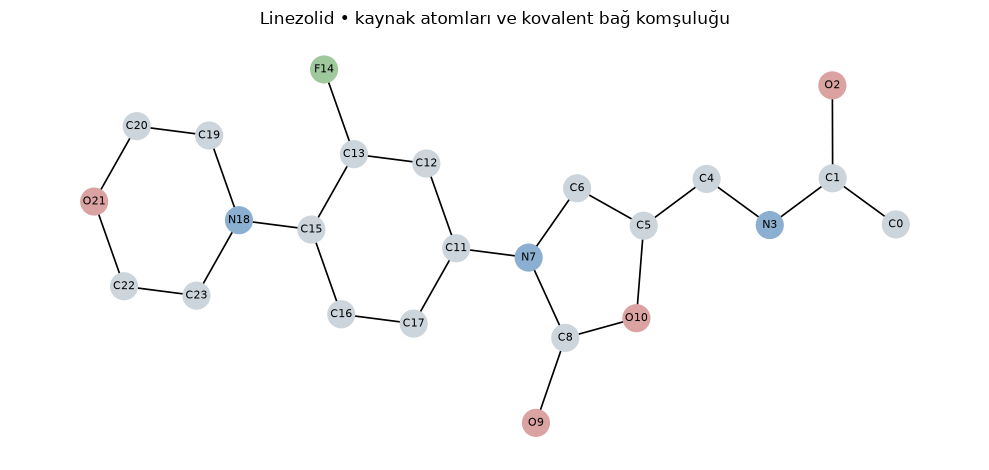

,atom,element,aromatik,CIP,ham_chiral_tag
0,0,C,False,yok/belirtilmemiş,CHI_UNSPECIFIED
1,1,C,False,yok/belirtilmemiş,CHI_UNSPECIFIED
2,2,O,False,yok/belirtilmemiş,CHI_UNSPECIFIED
3,3,N,False,yok/belirtilmemiş,CHI_UNSPECIFIED
4,4,C,False,yok/belirtilmemiş,CHI_UNSPECIFIED
5,5,C,False,S,CHI_TETRAHEDRAL_CW
6,6,C,False,yok/belirtilmemiş,CHI_UNSPECIFIED
7,7,N,False,yok/belirtilmemiş,CHI_UNSPECIFIED
8,8,C,False,yok/belirtilmemiş,CHI_UNSPECIFIED
9,9,O,False,yok/belirtilmemiş,CHI_UNSPECIFIED


In [3]:

from wp04_chemistry import Chem,parse_smiles
from rdkit.Chem import rdDepictor
import networkx as nx
source=pd.read_csv(ROOT/'reports/qa/WP04/structure_sources.csv').set_index('id')
smiles=source.loc['DB00601','raw_smiles'];mol,status=parse_smiles(smiles);rdDepictor.Compute2DCoords(mol)
g=nx.Graph();g.add_nodes_from(range(mol.GetNumAtoms()))
g.add_edges_from((b.GetBeginAtomIdx(),b.GetEndAtomIdx()) for b in mol.GetBonds())
pos={i:(mol.GetConformer().GetAtomPosition(i).x,mol.GetConformer().GetAtomPosition(i).y) for i in g.nodes}
color={'C':'#cbd5db','N':'#8aafd0','O':'#dba2a2','F':'#9fc99c'}
fig,ax=plt.subplots(figsize=(10,4.8));nx.draw_networkx(g,pos,ax=ax,node_size=370,node_color=[color.get(mol.GetAtomWithIdx(i).GetSymbol(),'#dbc293') for i in g],labels={i:f'{mol.GetAtomWithIdx(i).GetSymbol()}{i}' for i in g},font_size=8,width=1.2)
ax.set_title('Linezolid • kaynak atomları ve kovalent bağ komşuluğu');ax.axis('off')
plt.tight_layout();plt.savefig(F/'02_Linezolid_atom_graph_preview.png',dpi=160);plt.show()
display(pd.DataFrame([{'atom':a.GetIdx(),'element':a.GetSymbol(),'aromatik':a.GetIsAromatic(),'CIP':a.GetProp('_CIPCode') if a.HasProp('_CIPCode') else 'yok/belirtilmemiş','ham_chiral_tag':str(a.GetChiralTag())} for a in mol.GetAtoms()]))


**Yorum:**Çizgi yalnız komşuluk gösterir;bağ derecesi/aromatiklik/stereo aşağıdaki ayrı edge_attr sözleşmesindedir. Bu görüntü eğitim tensörü veya çalıştırılmış moleküler encoder değildir. Atom indeksleri join/görsel içindir,ezberleme girdisi olmaz.2D koordinatlar çizim içindir;3D konformer veya model girdisi değildir.

## 3. Önerilen özellik ve kapasite sözleşmesi

,tür,alan,sabit_kategoriler,boyut
0,atom,element,"['C', 'N', 'O', 'F', 'P', 'S', 'Cl', 'Br', 'I', 'OTHER']",10
1,atom,total_degree,"[0, 1, 2, 3, 4, 5, 6, 'OTHER']",8
2,atom,formal_charge,"[-2, -1, 0, 1, 2, 'OTHER']",6
3,atom,total_H,"[0, 1, 2, 3, 4, 'OTHER']",6
4,atom,hybridization,"['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2', 'OTHER']",6
5,atom,aromatic,['bool'],1
6,atom,in_ring,['bool'],1
7,atom,CIP_state,"['R', 'S', 'UNASSIGNED_POTENTIAL', 'NONE', 'OTHER']",5
8,atom,isotope_specified,['bool'],1
9,bond,bond_type,"['SINGLE', 'DOUBLE', 'TRIPLE', 'AROMATIC', 'OTHER']",5


,alan,önerilen_sözleşme
0,x,"float32[N,44] proposed, not built"
1,edge_index,"int64[2,2B] two directions, no self-loop"
2,edge_attr,"float32[2B,14] proposed"
3,num_nodes,explicit N
4,y,absent; supervision separate by frozen train PT
5,batch,separate per-drug disjoint graphs; no cross-molecule edges


,train_PT,WP09_total,proposed_molecular_branch,proposed_total,proposed_increment
0,158,26356,1592,29370,3014
1,163,27066,1592,30125,3059
2,171,28202,1592,31333,3131
3,177,29054,1592,32239,3185
4,180,29480,1592,32692,3212
5,189,30758,1592,34051,3293
6,191,31042,1592,34353,3311
7,192,31184,1592,34504,3320
8,194,31468,1592,34806,3338
9,199,32178,1592,35561,3383


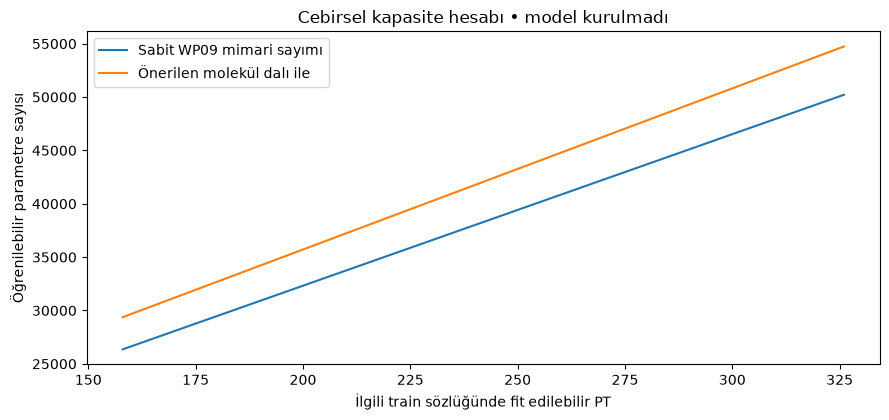

In [4]:

features=[]
for kind,fields in proposal['features'].items():
    for field,values in fields.items():features.append({'tür':kind,'alan':field,'sabit_kategoriler':str(values),'boyut':len(values)})
display(pd.DataFrame(features));display(pd.DataFrame(list(proposal['PyG_contract'].items()),columns=['alan','önerilen_sözleşme']))
budget=pd.read_csv(Q/'parameter_budget_by_train_PT.csv');display(budget)
fig,ax=plt.subplots(figsize=(9,4.3));ax.plot(budget.train_PT,budget.WP09_total,label='Sabit WP09 mimari sayımı');ax.plot(budget.train_PT,budget.proposed_total,label='Önerilen molekül dalı ile')
ax.set(xlabel='İlgili train sözlüğünde fit edilebilir PT',ylabel='Öğrenilebilir parametre sayısı',title='Cebirsel kapasite hesabı • model kurulmadı');ax.legend()
plt.tight_layout();plt.savefig(F/'03_proposed_parameter_budget.png',dpi=160);plt.show()


**Yorum:**44 atom/14 bağ alanı sabit kategorilerle önerilir;OTHER desteklenir,testten sözlük öğrenilmez. CIP R/S,belirtilmemiş potansiyel ve stereo-yok ayrıdır. Ham chiralTag/bond direction metadata korunur;komşu sırasına bağlı ham işaretler doğrudan sayısal özellik yapılmaz. İzotop/radikal mevcut kaynakta0;yeni örnekte ayrı QC gerekir.

Öneri bir bond-aware residual mean katmanı hidden16,mean readout→8 ve mevcut141 temsile8+maske ekleyerek150 boyuttur. Yeni dal1592 parametre,PT başlığına9K ek parametre;toplam5512+151K. Mevcut K158–326 için29.370–54.738 parametre,bağımsız örnekler yalnız train ilaçlarıdır. Çok PT daha çok bağımsız ilaç sağlamaz;aşırı öğrenme riski sürer. Edge-conditioned büyük NNConv zorunlu değil;küçük açık mesaj denklemi önerildi. Bir katman yalnız yerel komşuluk taşır;derin kimyasal mekanizma/3D stereo etkileşim çözümü iddia edilmez.

## 4. Ablation ve onay kapısı

In [5]:

display(pd.DataFrame([{'hücre':name,'atom_mesajı':name[1]=='1','insan_PPI_mesajı':name[-1]=='1','durum':'ÖNERİ; uygulanmadı'} for name in proposal['factorial_primary']]))
display(pd.DataFrame({'onay_bekleyen':proposal['remaining_gates']}))
display(pd.DataFrame(json.loads((Q/'method_sources.json').read_text(encoding='utf-8'))['sources']))


,hücre,atom_mesajı,insan_PPI_mesajı,durum
0,A0_P0,False,False,ÖNERİ; uygulanmadı
1,A0_P1,False,True,ÖNERİ; uygulanmadı
2,A1_P0,True,False,ÖNERİ; uygulanmadı
3,A1_P1,True,True,ÖNERİ; uygulanmadı


,onay_bekleyen
0,Approve strict54 atom mask and keep eight review holds
1,"Approve 44/14 schema, one-layer16/8 architecture and150 fusion"
2,"Approve factorial scope, common inner mask and optional null cost"
3,Approve future implementation/encoder tests separately; training requires explicit authorization


,title,url
0,RDKit Book: aromaticity/stereochemistry,https://www.rdkit.org/docs/RDKit_Book.html
1,PyG Data shapes,https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.data.Data.html
2,"PyG NNConv edge-conditioned messages (alternative, not proposed instantiated architecture)",https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.NNConv.html
3,PyG global_mean_pool,https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.pool.global_mean...


**Yorum:**A0P0/A0P1/A1P0/A1P1 gelecekte aynı genişletilmiş mimari/init/ID/PT kapsamında kıyaslanır. Atom katkısı aynı PPI koşulunda,PPI katkısı aynı atom koşulunda ölçülür. Eski WP09 A0 modeli yeni başlık/kapasiteyi taşımadığından tek başına kontrollü factorial hücre yerine geçmez;sabit tarihsel referans kalır. R0/R1/R2 eklenirse aynı v3 null/NA/ortak-inner politikası ve metrik ortalaması korunur.

Eski split/hash,train-only PT sözlüğü/scaler/uygunluk ve paired54/own61 korunur. Query atom grafı bağımsız okunur;protein train cache'ine/diğer ilaç grafına geri mesaj yoktur. Unknown gerçek negatif değildir. Karşılaştırmalar önceki sonuçlar görülmüş olduğu için keşifseldir;klinik risk iddiası yoktur.

Mevcut yol haritası küçük moleküler GNN'yi izinli konu yapar;bu tasarım tam moleküler Graph-in-Graph tamamlandı anlamına gelmez. İç atom grafı→drug readout ve protein-PPI füzyonu gerçek forward/gradient/permutation/edge-attr/split izolasyon testleriyle uygulanmadan bu iddia kurulamaz. **Tasarım önerisi hazır;uygulama ve özellikle eğitim için kullanıcı onayı beklenir.**

Yöntem kaynakları: [RDKit stereo/aromatiklik](https://www.rdkit.org/docs/RDKit_Book.html),[PyG Data şekilleri](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.data.Data.html),[graph mean readout](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.pool.global_mean_pool.html). Bunlar yöntem belgesidir,yeni biyolojik kaynak değildir.